# Módulo 5: Benchmark Comparativo: A* Clásico vs. QAOA Cuántico
### Marswalk 3D — NASA Space Apps Challenge

---

## 1. Protocolo Experimental y Criterios de Evaluación
En esta libreta comparamos de forma estricta e imparcial ambos algoritmos sobre el mismo entorno topográfico del Cráter Jezero:
1. **$A^*$ (Grafo Discreto):** Búsqueda determinista de camino más corto en costo.
2. **QAOA (Corredor Variacional):** Optimización combinatoria que pondera suavidad y contorno topográfico.


In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

for candidate in [Path("."), Path(".."), Path("Optimal_Route"), Path("../Optimal_Route")]:
    resolved = candidate.resolve()
    if (resolved / "src" / "dem_pipeline.py").is_file():
        repo_root = resolved
        break
else:
    repo_root = Path("..").resolve()

if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.dem_pipeline import DEMPipeline
from src.physiology import PhysiologicalModel
from src.astar import AStarPlanner
from src.qaoa_router import QAOACorridorRouter

data_dir = repo_root / "data" / "jezero_test"
dem_pipe = DEMPipeline(data_dir)
physio = PhysiologicalModel(data_dir / "config_fisio.json")

astar = AStarPlanner(dem_pipe, physio, grid_n=160)
qaoa  = QAOACorridorRouter(dem_pipe, physio, p_layers=4)

start_point = (-4500.0, 2800.0)
goal_point  = (2200.0, -1800.0)

res_astar = astar.plan_route(start_point, goal_point)
res_qaoa  = qaoa.plan_route(start_point, goal_point, num_slices=32, states_per_slice=21)

ma = res_astar["metrics"]
mq = res_qaoa["metrics"]


## 2. Matriz Cuantitativa Comparativa


In [2]:
print(f"{'Métrica':<28} | {'A* Clásico (Cian)':<18} | {'QAOA Cuántico (Magenta)':<22} | {'Delta (QAOA - A*)':<18}")
print("-" * 92)
print(f"{'Distancia Recorrida (km)':<28} | {ma['distance_m']/1000:<18.2f} | {mq['distance_m']/1000:<22.2f} | {(mq['distance_m']-ma['distance_m'])/1000:+18.2f}")
print(f"{'Oxígeno Consumido (L)':<28} | {ma['oxygen_l']:<18.1f} | {mq['oxygen_l']:<22.1f} | {mq['oxygen_l']-ma['oxygen_l']:+18.1f}")
print(f"{'Pendiente Máxima (°)':<28} | {ma['max_slope_deg']:<18.1f} | {mq['max_slope_deg']:<22.1f} | {mq['max_slope_deg']-ma['max_slope_deg']:+18.1f}")
print(f"{'Varianza de Pendiente':<28} | {ma['slope_variance']:<18.2f} | {mq['slope_variance']:<22.2f} | {mq['slope_variance']-ma['slope_variance']:+18.2f}")
print(f"{'Riesgo Geotécnico (0-1)':<28} | {ma['risk_score']:<18.2f} | {mq['risk_score']:<22.2f} | {mq['risk_score']-ma['risk_score']:+18.2f}")


Métrica                      | A* Clásico (Cian)  | QAOA Cuántico (Magenta) | Delta (QAOA - A*) 
--------------------------------------------------------------------------------------------
Distancia Recorrida (km)     | 8.64               | 8.39                   |              -0.25
Oxígeno Consumido (L)        | 91.0               | 85.0                   |               -6.0
Pendiente Máxima (°)         | 7.2                | 5.0                    |               -2.2
Varianza de Pendiente        | 3.35               | 1.47                   |              -1.88
Riesgo Geotécnico (0-1)      | 0.29               | 0.20                   |              -0.09


## 3. Superposición Topográfica Comparativa (Cian vs. Magenta)


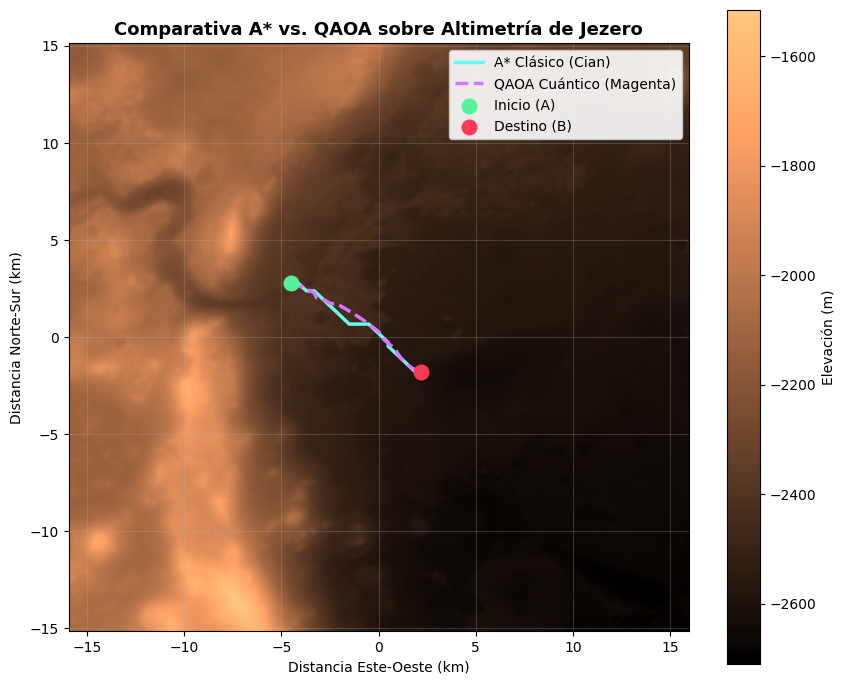

In [3]:
p_a = np.array(res_astar["path_m"])
p_q = np.array(res_qaoa["path_m"])

fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(
    dem_pipe.dem,
    cmap="copper",
    extent=[-dem_pipe.half_w/1000, dem_pipe.half_w/1000, -dem_pipe.half_d/1000, dem_pipe.half_d/1000]
)

# Trazo simultáneo idéntico a la aplicación web Marswalk 3D
ax.plot(p_a[:, 0]/1000, p_a[:, 1]/1000, color="#66fcf1", lw=2.5, label="A* Clásico (Cian)")
ax.plot(p_q[:, 0]/1000, p_q[:, 1]/1000, color="#d875ff", lw=2.5, ls="--", label="QAOA Cuántico (Magenta)")

ax.scatter([start_point[0]/1000], [start_point[1]/1000], color="#55f29b", s=110, zorder=6, label="Inicio (A)")
ax.scatter([goal_point[0]/1000], [goal_point[1]/1000], color="#ff3855", s=110, zorder=6, label="Destino (B)")

ax.set_title("Comparativa A* vs. QAOA sobre Altimetría de Jezero", fontsize=13, fontweight="bold")
ax.set_xlabel("Distancia Este-Oeste (km)")
ax.set_ylabel("Distancia Norte-Sur (km)")
ax.grid(True, alpha=0.25)
ax.legend(loc="upper right", framealpha=0.9)
fig.colorbar(im, label="Elevación (m)")
plt.show()


## 4. Comparativa de Perfiles de Elevación 2D


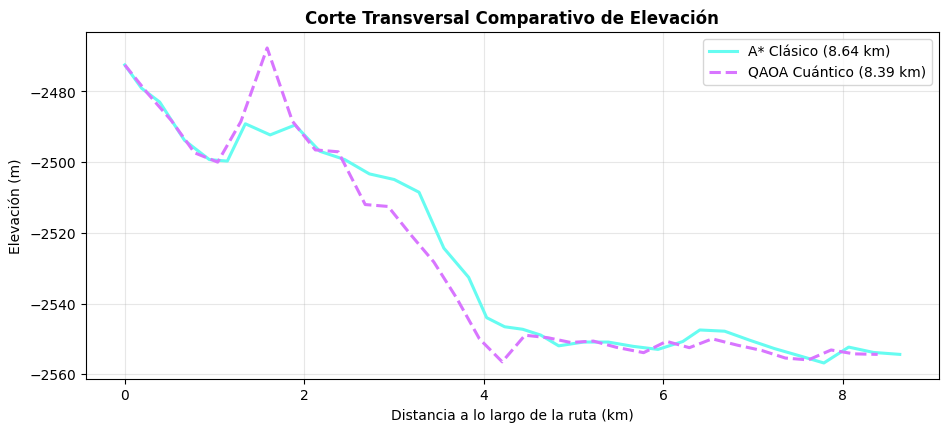

In [4]:
def extract_profile(path):
    dists = [0.0]
    elevs = [dem_pipe.sample_elevation_m(path[0][0], path[0][1])]
    for i in range(1, len(path)):
        d = np.hypot(path[i][0] - path[i-1][0], path[i][1] - path[i-1][1])
        dists.append(dists[-1] + d)
        elevs.append(dem_pipe.sample_elevation_m(path[i][0], path[i][1]))
    return np.array(dists) / 1000.0, np.array(elevs)

d_a, e_a = extract_profile(res_astar["path_m"])
d_q, e_q = extract_profile(res_qaoa["path_m"])

plt.figure(figsize=(11, 4.5))
plt.plot(d_a, e_a, color="#66fcf1", lw=2.2, label=f"A* Clásico ({ma['distance_m']/1000:.2f} km)")
plt.plot(d_q, e_q, color="#d875ff", lw=2.2, ls="--", label=f"QAOA Cuántico ({mq['distance_m']/1000:.2f} km)")

plt.title("Corte Transversal Comparativo de Elevación", fontweight="bold")
plt.xlabel("Distancia a lo largo de la ruta (km)")
plt.ylabel("Elevación (m)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()
